# Chapter 23 — Short-Dated Options, Dealer Positioning, and Market Feedback

The chapter's 0DTE arithmetic, rebuilt from the Black–Scholes–Merton formula and made
to reproduce the chapter's numbers. **NumPy only** (matplotlib for the plots). One
setting runs through every section: the S&P 500 at 5000, volatility 15%, a 4% rate and
a 1.5% dividend yield, with time counted in trading hours, 6.5 to the day and 252 days
to the year. One hour to expiration is therefore $T = 1/(6.5 \times 252) = 1/1638$ of a year.

| Section | What is built | Text |
|---|---|---|
| 1 | The formula, its Greeks on the trading clock, a `show` helper | — |
| 2 | The Greeks as expiration approaches | Table 23.1 |
| 3 | The gamma band and where a one-hour book's gamma sits | Figure 23.1, §23.2 |
| 4 | The buyer's arithmetic: decay, break-even, the cost of a tick | Example 23.1, Figure 23.2 |
| 5 | Charm: a billion dollars of hedging with the index unmoved | Example 23.2, Figure 23.3 |
| 6 | The overnight share of variance | §23.5 |
| 7 | The smile at zero maturity | §23.6, Figure 23.4 |
| 8 | How large the hedging flow is | Example 23.3 |
| 9 | A scheduled announcement | Example 23.4 |
| 10 | What a flat volatility gets wrong | Example 23.5, §23.9 |
| 11 | Pinning: the restoring force | Example 23.6 |
| 12 | Net dealer gamma under an assumed split | Example 23.7 |

Every computed figure is shown beside the number the chapter prints, with `ok` when
they agree to the chapter's rounding. Figures the chapter does not print are printed
without a book value.

## 1. The formula, the clock and a checking helper

`call` returns the Black–Scholes–Merton price, delta and gamma of a call with the
chapter's rate and yield; `put` follows from put–call parity. `DAY` and `HOUR` are the
trading clock. `show` prints a computed value beside the chapter's, with a tolerance of
half a unit in the last printed digit unless one is given.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import log, sqrt, exp, erf, pi

S0, SIG, R, Q = 5000.0, 0.15, 0.04, 0.015
DAY = 1.0 / 252.0          # one trading day, in years
HOUR = DAY / 6.5           # one trading hour: 1 / 1638 of a year


def N(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))


def n(x):
    return exp(-0.5 * x * x) / sqrt(2.0 * pi)


def call(S, K, T, sig=SIG):
    d1 = (log(S / K) + (R - Q + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    price = S * exp(-Q * T) * N(d1) - K * exp(-R * T) * N(d2)
    delta = exp(-Q * T) * N(d1)
    gamma = exp(-Q * T) * n(d1) / (S * sig * sqrt(T))
    return price, delta, gamma


def put(S, K, T, sig=SIG):
    return call(S, K, T, sig)[0] - S * exp(-Q * T) + K * exp(-R * T)


def show(label, got, printed, tol=None):
    # tol defaults to half a unit in the last printed digit
    if tol is None and isinstance(printed, int):
        tol = 0.5
    elif tol is None:
        s = repr(float(printed)).split(".")
        tol = 0.5 * 10 ** -len(s[1]) + 1e-12
    flag = "ok" if abs(got - printed) <= tol else "DIFFERS"
    print("%-56s %12.6g   book %10.6g   %s" % (label, got, printed, flag))


def note(label, got):
    print("%-56s %12.6g" % (label, got))


print("one hour = 1 / %.0f of a year" % (1 / HOUR))

one hour = 1 / 1638 of a year


## 2. The Greeks as expiration approaches — Table 23.1

An at-the-money call, priced at six times to expiration. Price falls with $\sqrt{T}$,
delta stays near one half, and gamma rises as $1/\sqrt{T}$. The last two columns are the
hedged P&L of a 1% rise in index points: the gamma term $\tfrac12 \Gamma (0.01 S)^2$ of the
Taylor expansion, and the exact value from repricing the option and taking off the delta
hedge. They agree at thirty days and part as the gamma band narrows: at one hour a 1% move
is 2.7 standard deviations and runs out of the band.

In [2]:
ROWS = (("30 days", 30 * DAY, 110.47, 0.5323, 0.001534, 1.92, 1.89),
        ("7 days", 7 * DAY, 51.58, 0.5158, 0.003188, 3.98, 3.90),
        ("1 day", DAY, 19.10, 0.5060, 0.008443, 10.55, 9.60),
        ("4 hours", 4 * HOUR, 14.94, 0.5047, 0.010763, 13.45, 11.65),
        ("1 hour", HOUR, 7.43, 0.5024, 0.021528, 26.91, 17.55),
        ("15 minutes", 0.25 * HOUR, 3.71, 0.5012, 0.043056, 53.82, 21.25))


def exact_pnl(T, move=0.01):
    # reprice after the move and take off the delta hedge
    p, d, _ = call(S0, S0, T)
    return call(S0 * (1 + move), S0, T)[0] - p - d * move * S0


print("%-11s %9s %8s %10s %11s %9s" % ("time left", "price", "delta", "gamma", "gamma term", "exact"))
for label, T, wp, wd, wg, wpl, wex in ROWS:
    p, d, g = call(S0, S0, T)
    print("%-11s %9.2f %8.4f %10.6f %11.2f %9.2f" % (label, p, d, g, 0.5 * g * (0.01 * S0) ** 2, exact_pnl(T)))
print()
for label, T, wp, wd, wg, wpl, wex in ROWS:
    p, d, g = call(S0, S0, T)
    show(label + ": price", p, wp)
    show(label + ": gamma", g, wg)
    show(label + ": gamma term", 0.5 * g * (0.01 * S0) ** 2, wpl)
    show(label + ": exact hedged P&L, 1% rise", exact_pnl(T), wex)
show("one-hour gamma / thirty-day gamma", call(S0, S0, HOUR)[2] / call(S0, S0, 30 * DAY)[2], 14.0, 0.1)

time left       price    delta      gamma  gamma term     exact
30 days        110.47   0.5323   0.001534        1.92      1.89
7 days          51.58   0.5158   0.003188        3.98      3.90
1 day           19.10   0.5060   0.008443       10.55      9.60
4 hours         14.94   0.5047   0.010763       13.45     11.65
1 hour           7.43   0.5024   0.021528       26.91     17.55
15 minutes       3.71   0.5012   0.043056       53.82     21.25

30 days: price                                                110.474   book     110.47   ok
30 days: gamma                                             0.00153357   book   0.001534   ok
30 days: gamma term                                           1.91696   book       1.92   ok
30 days: exact hedged P&L, 1% rise                            1.89461   book       1.89   ok
7 days: price                                                 51.5824   book      51.58   ok
7 days: gamma                                              0.00318762   book   0.00318

## 3. The gamma band — Figure 23.1

Gamma by strike, relative to the at-the-money value, at thirty days, one day and one
hour. The band's half-width is the move at which gamma falls to half its at-the-money
level; it narrows with $\sqrt{T}$, so at one hour almost all of a book's gamma sits
within one percent of spot.

30 days: band edge above spot, %                              6.75912   book       6.76   ok
30 days: band edge below spot, %                              5.51923   book       5.52   ok
1 day: band edge above spot, %                                 1.1334   book       1.13   ok
1 day: band edge below spot, %                                1.09225   book       1.09   ok
1 hour: band edge above spot, %                              0.439559   book       0.44   ok
1 hour: band edge below spot, %                              0.433229   book       0.43   ok
one-hour book: share of gamma within 0.5% of spot            0.822675
one-hour book: share of gamma within 1% of spot              0.993017


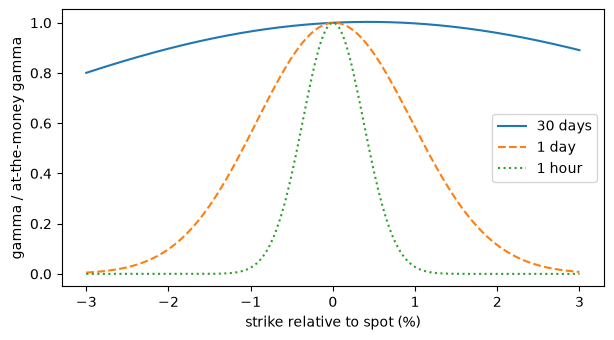

In [3]:
def edge(T, side=+1):
    # percentage move at which gamma falls to half its at-the-money value (bisection)
    g0 = call(S0, S0, T)[2]
    lo, hi = 0.0, 0.2
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if call(S0, S0 * (1 + side * mid), T)[2] / g0 > 0.5:
            lo = mid
        else:
            hi = mid
    return 100 * 0.5 * (lo + hi)


for label, T, up, down in (("30 days", 30 * DAY, 6.76, 5.52), ("1 day", DAY, 1.13, 1.09), ("1 hour", HOUR, 0.44, 0.43)):
    show(label + ": band edge above spot, %", edge(T, +1), up)
    show(label + ": band edge below spot, %", edge(T, -1), down)


def gamma_share(T, width, steps=20000):
    # share of gamma, summed over strikes 0.9 S to 1.1 S, within +/- width of spot
    K = S0 * np.linspace(0.9, 1.1, steps)
    g = np.array([call(S0, k, T)[2] for k in K])
    return g[np.abs(K / S0 - 1) <= width].sum() / g.sum()


note("one-hour book: share of gamma within 0.5% of spot", gamma_share(HOUR, 0.005))
note("one-hour book: share of gamma within 1% of spot", gamma_share(HOUR, 0.01))

m = np.linspace(-3, 3, 241)
fig, ax = plt.subplots(figsize=(7, 3.6))
for label, T, ls in (("30 days", 30 * DAY, "-"), ("1 day", DAY, "--"), ("1 hour", HOUR, ":")):
    g0 = call(S0, S0, T)[2]
    ax.plot(m, [call(S0, S0 * (1 + x / 100), T)[2] / g0 for x in m], ls, label=label)
ax.set_xlabel("strike relative to spot (%)")
ax.set_ylabel("gamma / at-the-money gamma")
ax.legend()
plt.show()

## 4. The buyer's arithmetic — Example 23.1 and Figure 23.2

A one-day at-the-money call costs 19.10, 0.38% of the index, against a one-standard-
deviation daily move of 0.94%: the buyer needs a move of about 0.4 standard deviations
just to recover the premium. With the index unmoved the option loses value faster as the
day goes on; the break-even move rises if the buyer waits to sell; and a one-tick
(ten-cent) spread is a growing fraction of a shrinking premium.

cost at the open                                              19.0952   book       19.1   ok
cost, % of the index                                         0.381903   book       0.38   ok
one-s.d. daily move, %                                       0.944911   book       0.94   ok
hurdle in standard deviations                                0.404168   book        0.4   ok

6.50 hours left: value                                        19.0952   book       19.1   ok
6.50 hours left: % of opening premium                             100   book        100   ok
4.00 hours left: value                                        14.9379   book      14.94   ok
4.00 hours left: % of opening premium                         78.2286   book         78   ok
2.00 hours left: value                                        10.5313   book      10.53   ok
2.00 hours left: % of opening premium                         55.1514   book         55   ok
1.00 hours left: value                                        7.43098

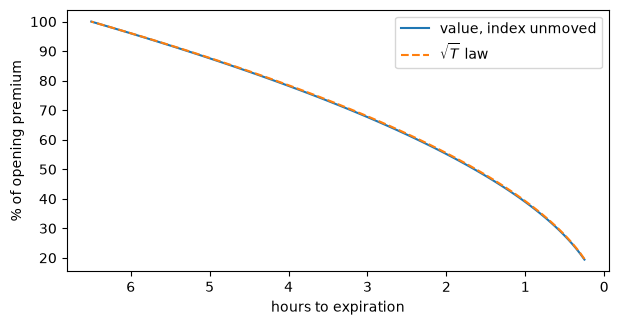

In [4]:
open_price = call(S0, S0, DAY)[0]
daily_sd = SIG * sqrt(DAY)
show("cost at the open", open_price, 19.10)
show("cost, % of the index", 100 * open_price / S0, 0.38)
show("one-s.d. daily move, %", 100 * daily_sd, 0.94)
show("hurdle in standard deviations", open_price / S0 / daily_sd, 0.4, 0.05)
print()
for hours, wv, wpct in ((6.5, 19.10, 100), (4, 14.94, 78), (2, 10.53, 55), (1, 7.43, 39), (0.25, 3.71, 19)):
    v = call(S0, S0, hours * HOUR)[0]
    show("%.2f hours left: value" % hours, v, wv)
    show("%.2f hours left: %% of opening premium" % hours, 100 * v / open_price, wpct)


def break_even(hours):
    # index move at which the call, held to this time, is worth its opening price
    lo, hi = S0, S0 * 1.02
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if call(mid, S0, hours * HOUR)[0] < open_price:
            lo = mid
        else:
            hi = mid
    return 100 * (0.5 * (lo + hi) / S0 - 1)


print()
show("break-even move, selling with 4 hours left, %", break_even(4), 0.15)
show("break-even move, selling with 2 hours left, %", break_even(2), 0.28)
show("break-even move, selling with 1 hour left, %", break_even(1), 0.35)
show("break-even move, selling with 15 minutes left, %", break_even(0.25), 0.38)
show("break-even move at expiration, %", 100 * open_price / S0, 0.38)
show("ten-cent spread at the open, % of premium", 100 * 0.10 / open_price, 0.52)
show("ten-cent spread at 15 minutes, % of premium", 100 * 0.10 / call(S0, S0, 0.25 * HOUR)[0], 2.7)

h = np.linspace(0.25, 6.5, 120)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(h, [100 * call(S0, S0, x * HOUR)[0] / open_price for x in h], label="value, index unmoved")
ax.plot(h, 100 * np.sqrt(h / 6.5), "--", label=r"$\sqrt{T}$ law")
ax.invert_xaxis()
ax.set_xlabel("hours to expiration")
ax.set_ylabel("% of opening premium")
ax.legend()
plt.show()

## 5. Charm — Example 23.2 and Figure 23.3

Dealers short 10,000 contracts of the 5025 call (0.5% out of the money) hold
$10{,}000 \times 100 \times \Delta$ units of the index as a hedge. With the index
unmoved all day, delta decays on the clock alone, and the rate of decay rises more than
eightfold between the open and the last half hour. Charm is computed here as the
central difference of delta in elapsed time.

delta of the 5025 call, 6.5 hours left                       0.304095   book     0.3041   ok
delta of the 5025 call, 5.0 hours left                       0.278096   book     0.2781   ok
delta of the 5025 call, 4.0 hours left                       0.254324   book     0.2543   ok
delta of the 5025 call, 3.0 hours left                       0.221652   book     0.2217   ok
delta of the 5025 call, 2.0 hours left                       0.172807   book     0.1728   ok
delta of the 5025 call, 1.0 hours left                      0.0901639   book     0.0902   ok
delta of the 5025 call, 0.5 hours left                      0.0287885   book     0.0288   ok

charm, per hour, 6.5 hours left                            -0.0146098   book    -0.0146   ok
charm, per hour, 4.0 hours left                             -0.027446   book    -0.0274   ok
charm, per hour, 2.0 hours left                            -0.0613704   book    -0.0614   ok
charm, per hour, 1.0 hours left                             -0.109898

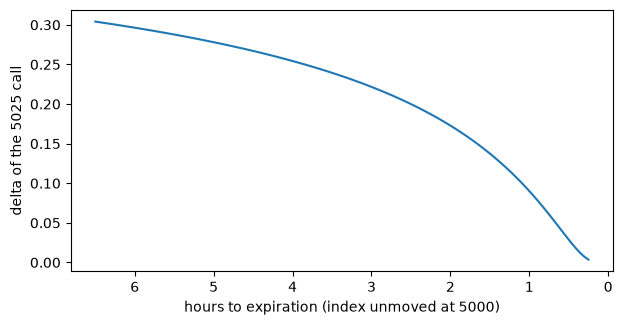

In [5]:
K = S0 * 1.005
DELTAS = {6.5: 0.3041, 5: 0.2781, 4: 0.2543, 3: 0.2217, 2: 0.1728, 1: 0.0902, 0.5: 0.0288}
for hrs, d in DELTAS.items():
    show("delta of the 5025 call, %.1f hours left" % hrs, call(S0, K, hrs * HOUR)[1], d)


def charm_per_hour(hrs):
    # instantaneous delta change per hour of elapsed time, at hrs hours to expiration
    eps = 1e-4 * HOUR
    return (call(S0, K, hrs * HOUR - eps)[1] - call(S0, K, hrs * HOUR + eps)[1]) / (2 * eps) * HOUR


print()
for hrs, c in ((6.5, -0.0146), (4, -0.0274), (2, -0.0614), (1, -0.1099), (0.5, -0.1254)):
    show("charm, per hour, %.1f hours left" % hrs, charm_per_hour(hrs), c)
note("last half hour's rate / the open's", charm_per_hour(0.5) / charm_per_hour(6.5))

units_open = 10000 * 100 * call(S0, K, 6.5 * HOUR)[1]
units_1h = 10000 * 100 * call(S0, K, HOUR)[1]
print()
show("hedge at the open, index units", units_open, 304095, 60)
show("hedge at the open, $bn", units_open * S0 / 1e9, 1.52)
show("hedge with one hour left, $m", units_1h * S0 / 1e6, 451)
show("unwound by the last hour, index unmoved, $bn", (units_open - units_1h) * S0 / 1e9, 1.07)

h = np.linspace(0.25, 6.5, 120)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(h, [call(S0, K, x * HOUR)[1] for x in h])
ax.invert_xaxis()
ax.set_xlabel("hours to expiration (index unmoved at 5000)")
ax.set_ylabel("delta of the 5025 call")
plt.show()

## 6. The overnight gap is not in the contract — §23.5

A 0DTE option lives only through the session, so it does not carry the overnight share
$\omega$ of close-to-close variance. On the trading-day clock its fair implied
volatility is the close-to-close volatility times $\sqrt{1-\omega}$.

In [6]:
for w, wv, wpct in ((0.1, 14.23, -5.1), (0.2, 13.42, -10.6), (0.3, 12.55, -16.3), (0.4, 11.62, -22.5)):
    v = 15 * sqrt(1 - w)
    show("omega = %.0f%%: session volatility, %%" % (100 * w), v, wv)
    show("omega = %.0f%%: difference from 15%%, %%" % (100 * w), 100 * (v / 15 - 1), wpct)

omega = 10%: session volatility, %                            14.2302   book      14.23   ok
omega = 10%: difference from 15%, %                          -5.13167   book       -5.1   ok
omega = 20%: session volatility, %                            13.4164   book      13.42   ok
omega = 20%: difference from 15%, %                          -10.5573   book      -10.6   ok
omega = 30%: session volatility, %                            12.5499   book      12.55   ok
omega = 30%: difference from 15%, %                           -16.334   book      -16.3   ok
omega = 40%: session volatility, %                             11.619   book      11.62   ok
omega = 40%: difference from 15%, %                          -22.5403   book      -22.5   ok


## 7. The smile at zero maturity — §23.6 and Figure 23.4

Extrapolated below a month, the at-the-money skew steepens as $T^{-0.4}$. From 2.5 volatility points per 1% of
moneyness at thirty days, the law gives the slope at shorter maturities. Figure 23.4
draws one stylized arbitrage-free (SVI) wing in $u = \psi(T)\,k$, $k$ in percent from
spot, so every curve is 15% at the money with slope $-\psi(T)$; the put wing steepens
sharply while the call wing barely moves.

7 days: steepness relative to 30 days                         1.78982   book       1.79   ok
7 days: slope, points per 1%                                  4.47455   book        4.5   ok
1 day: steepness relative to 30 days                          3.89806   book        3.9   ok
1 day: slope, points per 1%                                   9.74515   book        9.7   ok
1 hour: steepness relative to 30 days                         8.24164   book       8.24   ok
1 hour: slope, points per 1%                                  20.6041   book       20.6   ok

30 days: vol at the money, %                                  15.0005
30 days: slope at the money                                  -2.49984
7 days: vol at the money, %                                   15.0005
7 days: slope at the money                                   -4.49971
1 day: vol at the money, %                                    15.0005
1 day: slope at the money                                    -9.69938
1 hour: vol at the mo

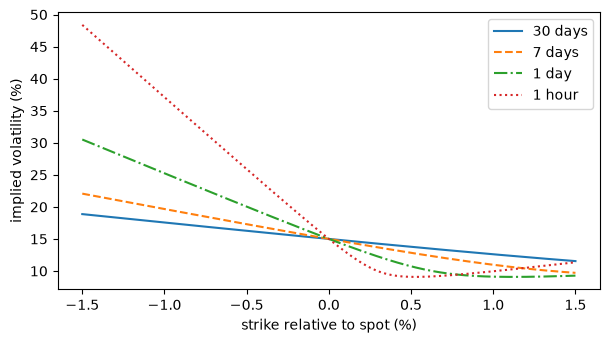

In [7]:
for label, T, wratio, wpts in (("7 days", 7 * DAY, 1.79, 4.5), ("1 day", DAY, 3.90, 9.7), ("1 hour", HOUR, 8.24, 20.6)):
    ratio = (30 * DAY / T) ** 0.4
    show(label + ": steepness relative to 30 days", ratio, wratio)
    show(label + ": slope, points per 1%", 2.5 * ratio, wpts)


def zsmile(k, psi):
    # stylized SVI wing, implied volatility in % at k percent from spot
    u = psi * k
    return 15 - 7.546 + 0.625 * (-0.76 * (u - 6.19) + np.sqrt((u - 6.19) ** 2 + 16))


PSI = (("30 days", 2.5, "-"), ("7 days", 4.5, "--"), ("1 day", 9.7, "-."), ("1 hour", 20.6, ":"))
print()
for label, psi, _ in PSI:
    slope = (zsmile(1e-4, psi) - zsmile(-1e-4, psi)) / 2e-4
    note(label + ": vol at the money, %", zsmile(0.0, psi))
    note(label + ": slope at the money", slope)
note("one hour: put 1% below spot, implied vol %", zsmile(-1.0, 20.6))

k = np.linspace(-1.5, 1.5, 301)
fig, ax = plt.subplots(figsize=(7, 3.6))
for label, psi, ls in PSI:
    ax.plot(k, zsmile(k, psi), ls, label=label)
ax.set_xlabel("strike relative to spot (%)")
ax.set_ylabel("implied volatility (%)")
ax.legend()
plt.show()

## 8. How large the hedging flow is — Example 23.3

Dealer gamma of \$500m per 1% move is about 930 one-hour contracts, or about 13,000
thirty-day ones. Gamma does not stay fixed at this horizon, so the true hedge on a fall
is smaller than the gamma figure suggests: about \$190m on a 0.5% fall, and it stops at
about \$230m once the move passes 1%, which is the book's whole delta.

In [8]:
per_contract = 0.01 * 100 * call(S0, S0, HOUR)[2] * S0 ** 2
per_30 = 0.01 * 100 * call(S0, S0, 30 * DAY)[2] * S0 ** 2
show("gamma per one-hour contract, $ per 1%", per_contract, 538200, 100)
show("one-hour contracts for $500m per 1%", 500e6 / per_contract, 930, 2)
show("thirty-day contracts for $500m per 1%", 500e6 / per_30, 13000, 100)

n_contracts = 500e6 / per_contract
d0 = call(S0, S0, HOUR)[1]
print()
for m, want in ((0.005, 190), (0.01, 230), (0.02, 230), (0.03, 230)):
    S1 = S0 * (1 - m)
    hedge = n_contracts * 100 * (d0 - call(S1, S0, HOUR)[1]) * S1 / 1e6
    show("true hedge on a %.1f%% fall, $m" % (100 * m), hedge, want, 8)

gamma per one-hour contract, $ per 1%                          538188   book     538200   ok
one-hour contracts for $500m per 1%                           929.043   book        930   ok
thirty-day contracts for $500m per 1%                         13041.5   book      13000   ok

true hedge on a 0.5% fall, $m                                 191.029   book        190   ok
true hedge on a 1.0% fall, $m                                 229.465   book        230   ok
true hedge on a 2.0% fall, $m                                 228.698   book        230   ok
true hedge on a 3.0% fall, $m                                 226.364   book        230   ok


## 9. A scheduled announcement — Example 23.4

With 20% of variance overnight, an ordinary session has a standard deviation of 0.845%
and a fair implied volatility of 13.4%. An announcement adds its own variance to the
session's. Two hours before a 1% event, the remaining variance is the ordinary
two hours plus the event, which annualizes to 31.6%; two minutes after it, only the
ordinary two hours are left and the implied volatility drops back to 13.4%.

In [9]:
session_sd = 100 * SIG * sqrt(DAY) * sqrt(0.8)
base_iv = 15 * sqrt(0.8)
show("ordinary session s.d., %", session_sd, 0.845, 0.0006)
show("ordinary session implied vol, %", base_iv, 13.4)
print()
for ev, wsd, wiv in ((0.5, 0.982, 15.6), (0.75, 1.130, 17.9), (1.0, 1.309, 20.8), (1.5, 1.722, 27.3)):
    sd = sqrt(session_sd ** 2 + ev ** 2)
    show("event s.d. %.2f%%: session s.d., %%" % ev, sd, wsd, 0.0006)
    show("event s.d. %.2f%%: implied vol, %%" % ev, base_iv * sd / session_sd, wiv)
rem = session_sd * sqrt(2.0 / 6.5)
before = sqrt(rem ** 2 + 1.0)
print()
show("two hours left, before the event: s.d., %", before, 1.104, 0.0006)
show("two hours left, after the event: s.d., %", rem, 0.469, 0.0006)
show("annualized before the event, %", base_iv * before / rem, 31.6)
show("before / after", before / rem, 2.36)

ordinary session s.d., %                                     0.845154   book      0.845   ok
ordinary session implied vol, %                               13.4164   book       13.4   ok

event s.d. 0.50%: session s.d., %                            0.981981   book      0.982   ok
event s.d. 0.50%: implied vol, %                              15.5885   book       15.6   ok
event s.d. 0.75%: session s.d., %                             1.12995   book       1.13   ok
event s.d. 0.75%: implied vol, %                              17.9374   book       17.9   ok
event s.d. 1.00%: session s.d., %                             1.30931   book      1.309   ok
event s.d. 1.00%: implied vol, %                              20.7846   book       20.8   ok
event s.d. 1.50%: session s.d., %                             1.72171   book      1.722   ok
event s.d. 1.50%: implied vol, %                              27.3313   book       27.3   ok

two hours left, before the event: s.d., %                     1.1044

## 10. What a flat volatility gets wrong — Example 23.5 and §23.9

Price a put below spot first at a flat 15% and then at the skewed volatility of
Section 23.6, extended linearly: 15% plus 2.5 points per 1% of moneyness at thirty days,
20.6 points at one hour. At thirty days the skew adds a tenth or a fifth to the price;
at one hour, a put 1% below spot (2.7 hourly standard deviations away) is worth more
than a hundred times its flat-volatility value.

In [10]:
FLATVOL = (("30 days", 30 * DAY, 2.5, 0.5, 83.99, 92.45, 16.2), ("30 days", 30 * DAY, 2.5, 1.0, 73.30, 89.90, 17.5),
           ("1 hour", HOUR, 20.6, 0.5, 0.75, 3.72, 25.3), ("1 hour", HOUR, 20.6, 1.0, 0.02, 2.75, 35.6))
for label, T, slope, pct, wflat, wskew, wvol in FLATVOL:
    Kp = S0 * (1 - pct / 100.0)
    sig = SIG + slope * pct / 100.0
    flat, skew = put(S0, Kp, T), put(S0, Kp, T, sig)
    show("%s, put %.1f%% below: flat-vol price" % (label, pct), flat, wflat)
    show("%s, put %.1f%% below: skewed vol, %%" % (label, pct), 100 * sig, wvol)
    show("%s, put %.1f%% below: skewed price" % (label, pct), skew, wskew)
    note("%s, put %.1f%% below: skewed / flat" % (label, pct), skew / flat)
print()
show("hourly s.d., %", 100 * SIG * sqrt(HOUR), 0.37)
show("1% below spot, in hourly standard deviations", 0.01 / (SIG * sqrt(HOUR)), 2.7)

30 days, put 0.5% below: flat-vol price                       83.9937   book      83.99   ok
30 days, put 0.5% below: skewed vol, %                          16.25   book       16.2   ok
30 days, put 0.5% below: skewed price                         92.4505   book      92.45   ok
30 days, put 0.5% below: skewed / flat                        1.10068
30 days, put 1.0% below: flat-vol price                       73.3012   book       73.3   ok
30 days, put 1.0% below: skewed vol, %                           17.5   book       17.5   ok
30 days, put 1.0% below: skewed price                         89.9015   book       89.9   ok
30 days, put 1.0% below: skewed / flat                        1.22647
1 hour, put 0.5% below: flat-vol price                       0.745277   book       0.75   ok
1 hour, put 0.5% below: skewed vol, %                            25.3   book       25.3   ok
1 hour, put 0.5% below: skewed price                          3.71944   book       3.72   ok
1 hour, put 0.5% below:

## 11. Pinning — Example 23.6

Dealers long 20,000 at-the-money calls with one hour left sell the index as it rises,
because their delta rises; that selling is the restoring force that holds the index near
a large strike. At one hour the force saturates: by a 1% move delta is almost one and
there is little left to sell. At thirty days the same position barely reacts.

In [11]:
UNITS = 20000 * 100
for label, T, moves in (("one hour", HOUR, ((0.10, 1063), (0.25, 2499), (0.50, 4114), (1.00, 4990))),
                        ("thirty days", 30 * DAY, ((0.50, 382), (1.00, 760)))):
    d0 = call(S0, S0, T)[1]
    for m, want in moves:
        S1 = S0 * (1 + m / 100.0)
        sell = UNITS * (call(S1, S0, T)[1] - d0) * S1 / 1e6
        show("%s, index up %.2f%%: dealers sell, $m" % (label, m), sell, want, 0.6)
note("one hour: delta after a 1% rise", call(S0 * 1.01, S0, HOUR)[1])

one hour, index up 0.10%: dealers sell, $m                    1063.15   book       1063   ok
one hour, index up 0.25%: dealers sell, $m                    2498.81   book       2499   ok
one hour, index up 0.50%: dealers sell, $m                    4114.23   book       4114   ok
one hour, index up 1.00%: dealers sell, $m                    4989.89   book       4990   ok
thirty days, index up 0.50%: dealers sell, $m                 382.218   book        382   ok
thirty days, index up 1.00%: dealers sell, $m                 759.797   book        760   ok
one hour: delta after a 1% rise                              0.996426


## 12. Net dealer gamma under an assumed split — Example 23.7

100,000 calls and 100,000 puts at one strike, identical gamma per contract. Public data
record that the contracts exist, not who holds which side, so a published gamma-exposure
figure has to assume a split: dealers long a fraction $w_c$ of the calls and short a
fraction $w_p$ of the puts. Net dealer gamma is $200{,}000\,(w_c - w_p)$ contracts'
worth, and its sign is decided by the assumption.

In [12]:
for wc, wp, want in ((1.0, 0.0, 200), (0.8, 0.2, 120), (0.6, 0.4, 40), (0.5, 0.5, 0), (0.4, 0.6, -40), (1.0, 1.0, 0)):
    net = 200 * (wc - wp)    # thousands of contracts' worth of gamma
    show("calls long %3.0f%% / puts short %3.0f%%: net, thousands" % (100 * wc, 100 * wp), net, want)

calls long 100% / puts short   0%: net, thousands                 200   book        200   ok
calls long  80% / puts short  20%: net, thousands                 120   book        120   ok
calls long  60% / puts short  40%: net, thousands                  40   book         40   ok
calls long  50% / puts short  50%: net, thousands                   0   book          0   ok
calls long  40% / puts short  60%: net, thousands                 -40   book        -40   ok
calls long 100% / puts short 100%: net, thousands                   0   book          0   ok


## What this notebook shows

* On the trading clock one hour is 1/1638 of a year, and every 0DTE number in the
  chapter follows from that clock and one Black–Scholes–Merton setting.
* Gamma rises as $1/\sqrt{T}$ while its band narrows as $\sqrt{T}$, so a one-hour book's
  hedging is concentrated near spot and enormous there.
* The buyer pays a premium that is small in dollars but needs a move of about 0.4
  standard deviations to recover it, and the cost of trading rises through the day.
* Charm moves a billion dollars of hedge with the index unmoved, on a schedule anyone
  can compute.
* The 0DTE smile is a different object: no overnight variance, a skew that steepens as
  $T^{-0.4}$, and puts below spot that a flat volatility prices at almost nothing.
* Pinning saturates, and published dealer gamma is an assumption about who holds what.

Every figure above is deterministic and reproduces the chapter.